# Capital stability measured on independent histories of known truth

**Question:** How unstable is the 99.9% operational-risk capital when it is estimated on independent histories of known truth, how fast does more history fix it, and how often does a bank near a tail index of 1 conclude the wrong thing about its mean loss?


- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 02, 06 and 07 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- describe the design of the stability experiment of case C17: four tail indices, two history lengths, two collection thresholds, 1,000 independent histories per cell, a known true quantile;
- read, from the committed documents, the dispersion, the bias, the share of underestimating histories and the number of histories on which each estimator is defined;
- reproduce the effect of the history length on the dispersion with fresh histories and the engine's `oprisk.capital_stability` test;
- measure how often a bank would conclude from its own data that the mean of its losses is infinite or finite when it is not;
- say precisely what the claim asserts, what its evidence is and what it does not assert.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The generator of case C17 and its estimators live in `data-pipeline/pipeline/cases/c17/`, which is not an installed package: this notebook loads those modules by path (importing the whole `pipeline` package would import every case and its heavy dependencies). The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

All four variants of case C17 (tail indices 0.6, 0.8, 0.96 and 1.1) of the synthetic bank.

- **Files read:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` and `xi-1-1.json`: `outputs.cells` (per cell, the replication seeds and the summary of each estimator over 1,000 histories, and the profile of the fitted tail index), `outputs.truth` (the true parameters and the true quantile with its Monte Carlo check) and `tests` (the committed `oprisk.capital_stability` rows).
- **What is committed and what is not:** the documents hold the summaries of 16,000 histories, not the histories. Fresh histories are generated from the case's generator, loaded by path as in notebook 02, with seeds outside the committed ranges.
- **What is synthetic:** the bank, its losses and the scenarios. The severity is exactly generalised Pareto above EUR 10,000, with the scale fitted to published medians of the Basel Committee's 2008 loss data exercise (BCBS, 2009, `derived-only`).

The next cell loads the documents and the generator.

In [2]:
# Load the four variant documents and the case's generator and estimator by path
ROOT = Path("../../..").resolve()
docs = {
    name: json.loads(
        (ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

print(
    "variants:", list(docs), "| baked by riskvalidation",
    {d["provenance"]["riskvalidation_version"] for d in docs.values()}, "| installed", md.version("riskvalidation")
)

variants: ['xi-0-6', 'xi-0-8', 'xi-0-96', 'xi-1-1'] | baked by riskvalidation {'1.1.0'} | installed 1.1.0


## Method

### Step 1: the design

The experiment crosses four tail indices, two history lengths (5 and 10 years) and two collection thresholds (EUR 10,000 and 20,000): 16 cells. In each cell the case simulates 1,000 histories from disjoint seed ranges, so that the histories are independent, records only the losses above the cell's threshold, and runs every estimator of the ladder on each. The true 99.9% quantile of the annual loss of each variant is known by construction: the Fourier method on a fine grid, checked by a Monte Carlo of 10,000,000 years. The next cell verifies from the documents that the 16 seed ranges do not overlap, and prints the Monte Carlo check of each truth.

In [3]:
# Check that the 16 seed ranges are disjoint and read the Monte Carlo check of each true quantile
ranges = []
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        rep = cell["replications"]
        ranges.append((rep["seed_first"], rep["seed_first"] + rep["n_replications"], name, cell["id"]))
ranges.sort()
overlaps = [(a[2:], b[2:]) for a, b in zip(ranges, ranges[1:]) if a[1] > b[0]]
print(
    "cells:", len(ranges), "| histories:", sum(r[1] - r[0] for r in ranges), "| overlapping seed ranges:",
    len(overlaps), "| failed replications:",
    sum(c["replications"]["n_failed"] for d in docs.values() for c in d["outputs"]["cells"])
)
for name, doc in docs.items():
    q = doc["outputs"]["truth"]["annual_loss_quantile"]
    print(
        "%-8s true quantile %15s | Monte Carlo check %15s +/- %12s (%.2f%%) | agrees within 3 se %s" % (
            name, format(q["value_eur"], ",.0f"), format(q["mc_check"]["value_eur"], ",.0f"),
            format(q["mc_check"]["standard_error_eur"], ",.0f"),
            100 * q["mc_check"]["standard_error_eur"] / q["value_eur"], q["mc_check"]["agrees"]
        )
    )

cells: 16 | histories: 16000 | overlapping seed ranges: 0 | failed replications: 0
xi-0-6   true quantile      33,897,000 | Monte Carlo check      33,806,597 +/-      173,397 (0.51%) | agrees within 3 se True
xi-0-8   true quantile     163,483,000 | Monte Carlo check     162,770,645 +/-    1,238,015 (0.76%) | agrees within 3 se True
xi-0-96  true quantile     634,865,452 | Monte Carlo check     629,494,317 +/-    5,917,877 (0.93%) | agrees within 3 se True
xi-1-1   true quantile   2,148,602,460 | Monte Carlo check   2,119,449,230 +/-   21,331,165 (0.99%) | agrees within 3 se True


Before judging estimators against the truth, the truth itself deserves one live check. The next cell recomputes the true 99.9% quantile of the variant with tail index 0.8 with the engine's Fourier method on the grid of the case, and puts it beside the committed value.

In [4]:
# Recompute the true 99.9% quantile of the variant with tail index 0.8 by the Fourier method
truth08 = docs["xi-0-8"]["outputs"]["truth"]
sev08 = (truth08["severity"]["tail_index"], truth08["severity"]["scale_eur"], truth08["severity"]["location_eur"])
grid_step = truth08["annual_loss_quantile"]["grid_step_eur"]
masses = aggregate.discretise_severity("gpd", sev08, grid_step, 2 ** 19)
pmf = aggregate.fft_aggregate("poisson", (truth08["frequency"]["lambda_per_year"],), masses, padding_factor=2)
q_fourier = aggregate.quantile_from_pmf(pmf, grid_step, 0.999)
print("mass beyond the grid: %.2e | recomputed quantile EUR %s | committed EUR %s" %
      (1.0 - pmf.sum(), format(q_fourier, ",.0f"), format(truth08["annual_loss_quantile"]["value_eur"], ",.0f")))

mass beyond the grid: 2.26e-04 | recomputed quantile EUR 163,483,000 | committed EUR 163,483,000


### Step 2: what is measured on each history

For an estimator with capital $\hat C_k$ on history $k$, the committed summaries over the 1,000 histories are, relative to the true quantile $C^\star$:

$$\text{bias} = \operatorname{median}_k(\hat C_k / C^\star) - 1, \qquad \text{dispersion} = \big(Q_{75} - Q_{25}\big)\big(\hat C_k / C^\star\big), \qquad \text{underestimation} = \frac{1}{1000}\sum_k \mathbf 1\{\hat C_k < C^\star\}$$

together with the number of histories on which the estimator returns a number: a fit that does not converge, a grid that does not reach the quantile or a mean that does not exist gives no capital, never a placeholder. The engine's `oprisk.capital_stability` computes the first two from an array of capitals. The next cell reads the splice estimator for the four variants and the four cells and prints the four quantities.

In [5]:
# The splice estimator in the 16 cells: bias, dispersion, share of underestimating histories, histories with a capital
print("%-8s %-11s %9s %11s %14s %9s" % ("", "", "bias", "dispersion", "underestimate", "defined"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        print(
            "%-8s %-11s %+9.3f %11.3f %14.3f %9d" % (
                name, cell["id"], splice["ratio_to_truth"]["median"] - 1.0, splice["iqr_over_truth"],
                splice["share_underestimating"], splice["n_defined"]
            )
        )

                          bias  dispersion  underestimate   defined
xi-0-6   y5-h10000      -0.236       1.952          0.558       959
xi-0-6   y5-h20000      -0.236       2.033          0.584       771
xi-0-6   y10-h10000     -0.150       1.429          0.559       996
xi-0-6   y10-h20000     -0.160       1.354          0.568       859
xi-0-8   y5-h10000      -0.337       2.744          0.587       904
xi-0-8   y5-h20000      -0.361       2.560          0.604       682
xi-0-8   y10-h10000     -0.184       1.776          0.552       971
xi-0-8   y10-h20000     -0.091       1.983          0.530       727
xi-0-96  y5-h10000      -0.219       3.104          0.566       725
xi-0-96  y5-h20000      -0.373       3.299          0.560       550
xi-0-96  y10-h10000     -0.236       2.111          0.546       818
xi-0-96  y10-h20000     -0.071       2.228          0.530       572
xi-1-1   y5-h10000      -0.502       3.304          0.568       229
xi-1-1   y5-h20000      -0.280       3.184      

### Step 3: the effect of the length of the history, on fresh histories

The committed summaries say the dispersion falls when the history goes from 5 to 10 years. We can check it with histories the case never used, and with the engine's own test. The next cell draws 40 new independent histories (seeds from 9,000,000) of the variant with tail index 0.8 for each of the two lengths at a threshold of EUR 10,000, runs the case's estimator (about 35 seconds in all) and applies `oprisk.capital_stability` to the splice capitals and to the single-loss approximation, against the true quantile. It also records the first value of each fitted tail-index profile, the one at the collection threshold. With only 40 histories the quartiles are noisy; the committed rows with 1,000 histories are printed beside them.

In [6]:
# Fresh independent histories of the variant with tail index 0.8, 5 and 10 years, threshold EUR 10,000
doc08 = docs["xi-0-8"]
variant = generator.variant(0.8)
bi = doc08["outputs"]["bank"]["business_indicator"]["bi_eur"]
true_q = doc08["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
fresh = {}
for years in (5, 10):
    seeds = [9_000_000 + 1000 * years + k for k in range(40)]
    fresh[years] = [replicate.estimate(variant, s, years, 10_000.0, bi, None, 20_000) for s in seeds]
fresh_rows = []
print(
    "%-6s %-6s %5s %11s %9s %8s | %s" % (
        "years", "rung", "n", "dispersion", "bias", "light", "committed over 1000: dispersion, bias"
    )
)
for years in (5, 10):
    cell = next(c for c in doc08["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)
    for rung in ("lda_splice", "sla"):
        capitals = np.array([r[rung] for r in fresh[years]])
        capitals = capitals[np.isfinite(capitals)]
        result = oprisk_tests.capital_stability(capitals, true_q, model_id=rung)
        stored = (cell["capital"][rung]["iqr_over_truth"], cell["capital"][rung]["ratio_to_truth"]["median"] - 1.0)
        fresh_rows.append((years, rung, capitals.size, result.metric, result.statistic, *stored))
        print(
            "%-6d %-6s %5d %11.3f %+9.3f %8s | %.3f %+.3f" % (
                years, rung, capitals.size, result.metric, result.statistic, result.light.value, *stored
            )
        )

years  rung       n  dispersion      bias    light | committed over 1000: dispersion, bias
5      lda_splice    37       6.116    +0.460      red | 2.744 -0.337
5      sla       40       1.915    +0.146      red | 1.284 -0.082
10     lda_splice    39       1.142    -0.305      red | 1.776 -0.184
10     sla       40       0.773    +0.063      red | 0.823 -0.075


The next cell draws the same four comparisons as bars: for the splice and the standardised approach at 5 and at 10 years, the dispersion and the bias on our 40 fresh histories beside the committed values over 1,000.

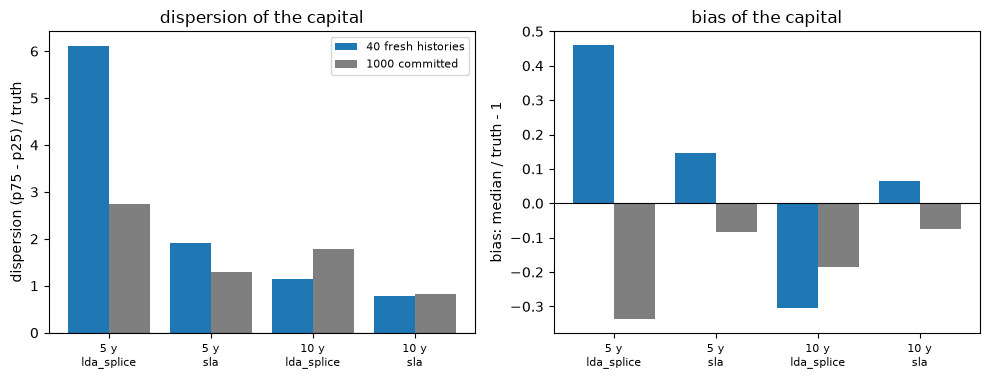

In [7]:
# Draw the dispersion and the bias of the fresh histories against the committed values
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
labels = ["%d y\n%s" % (r[0], r[1]) for r in fresh_rows]
pos = np.arange(len(labels))
panels = [(left, 3, 5, "dispersion (p75 - p25) / truth"), (right, 4, 6, "bias: median / truth - 1")]
for axis, fresh_col, stored_col, ylabel in panels:
    axis.bar(pos - 0.2, [r[fresh_col] for r in fresh_rows], 0.4, color="tab:blue", label="40 fresh histories")
    axis.bar(pos + 0.2, [r[stored_col] for r in fresh_rows], 0.4, color="tab:gray", label="1000 committed")
    axis.axhline(0.0, color="black", linewidth=0.8)
    axis.set_xticks(pos)
    axis.set_xticklabels(labels, fontsize=8)
    axis.set_ylabel(ylabel)
left.set_title("dispersion of the capital")
right.set_title("bias of the capital")
left.legend(fontsize=8)
fig.tight_layout()
plt.show()

On the left, forty fresh histories reproduce the direction of the committed result: the splice dispersion falls when the history doubles, from 6.116 to 1.142 here and from 2.744 to 1.776 over 1,000 histories. The fresh bars are far from the committed ones at 5 years because forty histories cannot pin down a quantile of a heavy-tailed ratio, and the splice is defined on only 37 and 39 of them. On the right the bias flips sign between samples. So the fresh run confirms the effect of length, not its size; the committed bars carry the size.

### Step 4: how often does a bank conclude the wrong thing about the mean?

A tail index of 1 or more means that the mean annual loss does not exist. The documents record, for every cell, the share of histories whose generalised Pareto tail index, fitted at the collection threshold, is 1 or more (`share_at_least_one`). It is the probability that a bank with that history length would conclude, from its own data alone, that its mean loss is infinite. The next cell prints it for the 16 cells, beside the share that concludes the opposite when the truth is 1 or more.

In [8]:
# The share of histories whose fitted tail index reaches 1, in the 16 cells (profile at the collection threshold)
print("%-8s %-11s %9s %-30s" % ("", "", "xi >= 1", "wrong conclusion"))
for name, doc in docs.items():
    true_xi = doc["outputs"]["tail_index"]
    for cell in doc["outputs"]["cells"]:
        share = cell["threshold_stability"][0]["share_at_least_one"]
        wrong = share if true_xi < 1 else 1.0 - share
        verdict = "infinite mean concluded" if true_xi < 1 else "finite mean concluded"
        print("%-8s %-11s %9.3f %-30s %.3f" % (name, cell["id"], share, verdict, wrong))

                       xi >= 1 wrong conclusion              
xi-0-6   y5-h10000       0.000 infinite mean concluded        0.000
xi-0-6   y5-h20000       0.000 infinite mean concluded        0.000
xi-0-6   y10-h10000      0.000 infinite mean concluded        0.000
xi-0-6   y10-h20000      0.000 infinite mean concluded        0.000
xi-0-8   y5-h10000       0.024 infinite mean concluded        0.024
xi-0-8   y5-h20000       0.063 infinite mean concluded        0.063
xi-0-8   y10-h10000      0.005 infinite mean concluded        0.005
xi-0-8   y10-h20000      0.012 infinite mean concluded        0.012
xi-0-96  y5-h10000       0.332 infinite mean concluded        0.332
xi-0-96  y5-h20000       0.344 infinite mean concluded        0.344
xi-0-96  y10-h10000      0.268 infinite mean concluded        0.268
xi-0-96  y10-h20000      0.317 infinite mean concluded        0.317
xi-1-1   y5-h10000       0.818 finite mean concluded          0.182
xi-1-1   y5-h20000       0.732 finite mean concluded  

The claim about the mean can be run too. The next cell draws 200 fresh histories for each variant and length (seeds from 9,200,000, with the collection threshold of EUR 10,000), fits the tail index at the threshold with the engine's `tail_index_profile` and counts how many reach 1, beside the committed share of the same cell.

In [9]:
# Fit the tail index at the collection threshold on 200 fresh histories per variant and length and count those
# reaching 1
share_live = {}
print("%-8s %5s | %12s | %s" % ("", "years", "fresh, xi>=1", "committed, xi>=1"))
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    for years in (5, 10):
        first = 9_200_000 + 10_000 * k + 1000 * years
        xi_hat = []
        for seed in range(first, first + 200):
            amounts = generator.draw_history(variant_k, seed, years).recorded(10_000.0).amounts
            xi_hat.append(distributions.tail_index_profile(amounts, np.array([10_000.0])).xi[0])
        share_live[(name, years)] = float(np.mean(np.array(xi_hat) >= 1.0))
        cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)
        print(
            "%-8s %5d | %12.3f | %.3f" % (
                name, years, share_live[(name, years)], cell["threshold_stability"][0]["share_at_least_one"]
            )
        )

         years | fresh, xi>=1 | committed, xi>=1
xi-0-6       5 |        0.000 | 0.000
xi-0-6      10 |        0.000 | 0.000
xi-0-8       5 |        0.020 | 0.024
xi-0-8      10 |        0.000 | 0.005
xi-0-96      5 |        0.270 | 0.332
xi-0-96     10 |        0.255 | 0.268
xi-1-1       5 |        0.805 | 0.818
xi-1-1      10 |        0.935 | 0.912


A bank near 1 also sees its tail index drift with the threshold. The next cell runs the engine's `oprisk.threshold_stability` on the profile of 100 fresh ten-year histories for the two variants closest to 1 and counts the lights.

In [10]:
# The threshold-stability test on the profile of 100 fresh ten-year histories, tail index 0.96 and 1.1
for k, name in enumerate(("xi-0-96", "xi-1-1")):
    variant_k = generator.variant(docs[name]["outputs"]["tail_index"])
    counts = {"green": 0, "amber": 0, "red": 0}
    for seed in range(9_300_000 + 1000 * k, 9_300_000 + 1000 * k + 100):
        amounts = generator.draw_history(variant_k, seed, 10).recorded(10_000.0).amounts
        profile = distributions.tail_index_profile(amounts, 10_000.0 * np.array([1.0, 2.0, 4.0, 8.0]))
        xi_profile = np.where(profile.converged, profile.xi, np.nan)
        light = oprisk_tests.threshold_stability(profile.thresholds, xi_profile, model_id="lda-splice").light.value
        counts[light] += 1
    print(name, "| lights of 100 histories:", counts)

xi-0-96 | lights of 100 histories: {'green': 21, 'amber': 66, 'red': 13}
xi-1-1 | lights of 100 histories: {'green': 17, 'amber': 59, 'red': 24}


### Step 5: what the stability does not come from

The dispersion could in principle come from the simulation used to build the truth or the estimators, not from the data. The truth's Monte Carlo check has a standard error under 1% of the quantile (step 1), the splice and the Panjer rungs have no Monte Carlo at all, and the case records that the Panjer and Fourier aggregations of the same fitted law agree on the histories where both exist (`aggregation_agreement`). So the dispersion of tens or hundreds of percent comes from estimating the tail on 5 or 10 years of losses. The next cell prints the largest relative difference between Panjer and Fourier over the cells, and the number of histories compared.

In [11]:
# The agreement between the Panjer and Fourier aggregations of the same fitted law, over the 16 cells
agreements = [c["aggregation_agreement"] for d in docs.values() for c in d["outputs"]["cells"]]
print(
    "largest relative difference Panjer - Fourier:", max(a["max_rel_diff_panjer_fft"] for a in agreements),
    "| histories compared:", sum(a["n_compared"] for a in agreements)
)

largest relative difference Panjer - Fourier: 0.000968054211 | histories compared: 11552


The standardised approach is the comparison the claim needs. The next cell computes its capital with the engine's `sma_capital` on 200 fresh ten-year histories of each variant and puts the median and the spread over the true quantile beside the committed values.

In [12]:
# The SMA capital over the true quantile on 200 fresh ten-year histories per variant
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    first = 9_400_000 + 1000 * k
    histories = [generator.draw_history(variant_k, s, 10).recorded(10_000.0) for s in range(first, first + 200)]
    ratios = np.array([sma.sma_capital(bi_k, h.annual).orc for h in histories]) / truth_q
    q25, q50, q75 = np.percentile(ratios, [25, 50, 75])
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h10000")["sma"]["orc_over_true_quantile"]
    print(
        "%-8s SMA / truth: median %.3f, IQR %.3f | committed: median %.3f, IQR %.3f" % (
            name, q50, q75 - q25, cell["median"], cell["p75"] - cell["p25"]
        )
    )

xi-0-6   SMA / truth: median 4.017, IQR 0.140 | committed: median 4.030, IQR 0.144
xi-0-8   SMA / truth: median 0.881, IQR 0.061 | committed: median 0.882, IQR 0.058
xi-0-96  SMA / truth: median 0.240, IQR 0.025 | committed: median 0.242, IQR 0.030
xi-1-1   SMA / truth: median 0.077, IQR 0.014 | committed: median 0.078, IQR 0.016


## Comparison

What is known before this notebook, from the notebooks and sources of this topic. Operational-risk capital by the loss distribution approach (LDA) is a high quantile of a compound sum whose tail is estimated from a few years of losses collected above a threshold (notebooks 01 and 02; Chavez-Demoulin, Embrechts and Neslehova, 2006; Shevchenko, 2010). The error of the Monte Carlo quantile is known to decay like the square root of the number of simulated years (Shevchenko, 2010). The Basel Committee removed the advanced approach for its complexity and the lack of comparability of internal models (BCBS, 2016), and the academic critique of its replacement argued that the standardised approach is itself unstable and insensitive to risk (Peters, Shevchenko, Hassani and Chapelle, 2016). The research behind this case illustrates the instability of an LDA near a tail index of 1 with one calibration of the Basel Committee's 2008 loss data medians (BCBS, 2009), with caveats. What those sources do not provide, as far as the research found, is the dispersion of the LDA capital against a known truth, measured over many independent histories and several tail indices, history lengths and thresholds.

## Evidence

**The instability of operational-risk capital, measured on independent histories of known truth.**

- **What it adds.** For four tail indices (0.6, 0.8, 0.96 and 1.1), two history lengths (5 and 10 years) and two collection thresholds (EUR 10,000 and 20,000), the case simulates 1,000 independent histories per cell on disjoint seed ranges (16,000 histories). For each rung of a six-rung estimation ladder and for the standardised approach it records the 99.9% capital against the true annual-loss quantile of the generator, as the median over the truth, the interquartile range over the truth, the share of histories that underestimate, and the number of histories on which the rung is defined; and the share of histories whose fitted tail index reaches 1, that is, that would conclude an infinite mean. On the committed grid the interquartile range of the splice rung is 1.35 to 3.30 times the truth, all 92 `oprisk.capital_stability` rows are red against stated internal gates, 27% to 34% of the histories of the variant with tail index 0.96 conclude an infinite mean that does not exist, and 9% to 27% of those of the variant with tail index 1.1 conclude a finite one (26.8 to 34.4% and 8.8 to 26.8% in the instability paper). These four statements were written into the design after the same 16,000 histories had been drawn, so they restate the bake and are reproduced by the paper, not tests that could have failed; the 92 red rows are those of the six-rung ladder, and all 144 rows of the nine rungs the paper counts, with the four robust rungs, are red too.
- **Evidence.** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` and `xi-1-1.json` (`outputs.cells`, `outputs.truth`, `tests`), the requirements CT-1701 to CT-1715 of `docs/design/features/c17/requirements.md`, and this notebook, which checks the design, reproduces the effect of the length with fresh histories and the engine's test, and prints the numbers.
- **The practice it goes beyond.** The research presents the instability near a tail index of 1 as a teaching case from one illustrative calibration, with caveats; the Basel Committee gives complexity and lack of comparability, not a measurement of error, as its reason for removing the advanced approach; the academic critique argues instability of the standardised approach. None of the sources found measures the dispersion of the LDA capital against a known truth over independent histories. That absence is UNVERIFIED beyond the research's own search.
- **What the claim does not say.** It does not say that the LDA is unusable or that the standardised approach is right: the standardised approach is not calibrated to a 99.9% quantile and is compared here only to the generator's. It is about a synthetic bank whose severity is drawn from the family the tail estimators assume (which favours the estimators) and whose lights use Contraste's own gates; it says nothing about the capital of any real bank.

In [13]:
# The evidence of the claim in one table: the splice and the standardised approach in the 10-year cells, and the
# wrong conclusions about the mean
print("%-8s %-11s %12s %12s %10s %10s %12s" % ("", "", "splice IQR", "defined", "SMA / truth", "xi >= 1", "true xi"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        if not cell["id"].startswith("y10"):
            continue
        print(
            "%-8s %-11s %12.3f %12d %10.3f %10.3f %12s" % (
                name, cell["id"], cell["capital"]["lda_splice"]["iqr_over_truth"],
                cell["capital"]["lda_splice"]["n_defined"], cell["sma"]["orc_over_true_quantile"]["median"],
                cell["threshold_stability"][0]["share_at_least_one"], doc["outputs"]["tail_index"]
            )
        )
rows = [t for d in docs.values() for t in d["tests"] if t["test_id"] == "oprisk.capital_stability"]
print(
    "committed capital-stability rows:", len(rows), "| red:", sum(t["light"] == "red" for t in rows),
    "| rows with a p-value:", sum(t["p_value"] is not None for t in rows)
)

                       splice IQR      defined SMA / truth    xi >= 1      true xi
xi-0-6   y10-h10000         1.429          996      4.030      0.000          0.6
xi-0-6   y10-h20000         1.354          859      3.975      0.000          0.6
xi-0-8   y10-h10000         1.776          971      0.882      0.005          0.8
xi-0-8   y10-h20000         1.983          727      0.869      0.012          0.8
xi-0-96  y10-h10000         2.111          818      0.242      0.268         0.96
xi-0-96  y10-h20000         2.228          572      0.239      0.317         0.96
xi-1-1   y10-h10000         1.683          128      0.078      0.912          1.1
xi-1-1   y10-h20000         2.319          409      0.077      0.836          1.1
committed capital-stability rows: 156 | red: 156 | rows with a p-value: 0


The next cell draws the committed evidence of the claim, in two figures. The first is the dispersion of the splice capital over the truth for each tail index, with 5 and with 10 years of data, from the cells with a threshold of EUR 10,000.

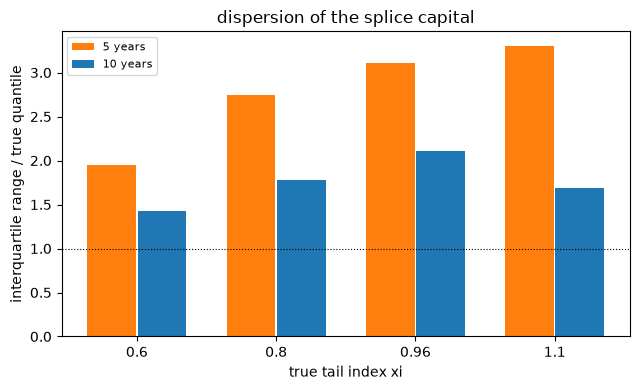

In [14]:
# Draw the dispersion of the splice capital for each tail index and history length
fig, ax = plt.subplots(figsize=(6.5, 4.0))
labels = [str(d["outputs"]["tail_index"]) for d in docs.values()]
positions = np.arange(len(labels))
for offset, years, color in ((-0.18, 5, "tab:orange"), (0.18, 10, "tab:blue")):
    cells_y = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years) for d in docs.values()]
    iqr = [cell["capital"]["lda_splice"]["iqr_over_truth"] for cell in cells_y]
    ax.bar(positions + offset, iqr, width=0.35, color=color, label="%d years" % years)
ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("true tail index xi")
ax.set_ylabel("interquartile range / true quantile")
ax.set_title("dispersion of the splice capital")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Every bar is at or above the dotted line at 1: the range of the splice capital over 1,000 histories is as large as the true capital itself, with 5 years and still with 10, and it is largest, 3.30, for the heaviest tail with 5 years. Doubling the history lowers the bars from 1.95 to 1.43, 2.74 to 1.78, 3.10 to 2.11 and 3.30 to 1.68, a gain that never takes a variant below the truth's own size. The figure covers one threshold; the table above has the four cells.

The second figure is the share of histories whose fitted tail index reaches 1, so that the bank concludes its mean loss is infinite, for each tail index and history length.

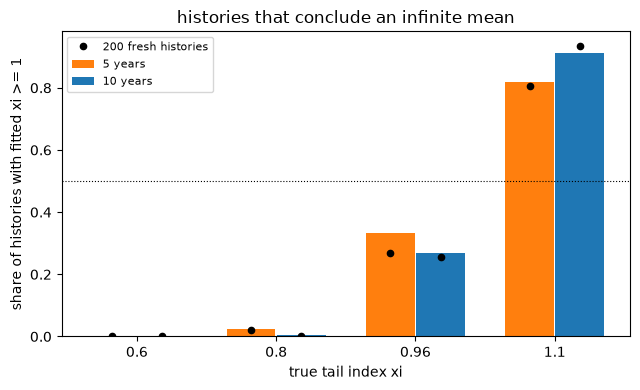

In [15]:
# Draw the share of histories whose fitted tail index reaches 1, by tail index and history length
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for offset, years, color in ((-0.18, 5, "tab:orange"), (0.18, 10, "tab:blue")):
    cells_y = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years) for d in docs.values()]
    share = [cell["threshold_stability"][0]["share_at_least_one"] for cell in cells_y]
    ax.bar(positions + offset, share, width=0.35, color=color, label="%d years" % years)
    ax.plot(positions + offset, [share_live[(n, years)] for n in docs], "k.", markersize=9)
ax.plot([], [], "k.", markersize=9, label="200 fresh histories")
ax.axhline(0.5, color="black", linewidth=0.8, linestyle=":")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("true tail index xi")
ax.set_ylabel("share of histories with fitted xi >= 1")
ax.set_title("histories that conclude an infinite mean")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

For tail indices 0.6 and 0.8 almost no history concludes an infinite mean, which is correct since the mean exists. At 0.96 more than a quarter of the histories call a finite mean infinite, and at 1.1 the bars are tall but not full: the remaining histories conclude a finite mean where none exists, 8.8% to 26.8% over the four cells of the table of step 4. The bank cannot read the answer from its own data near 1. The black dots are 200 fresh histories per cell, 0.270 and 0.255 at 0.96 and 0.805 and 0.935 at 1.1, close to the committed bars, so the shares are a property of the tail estimate and not of one batch of seeds. The figure uses the fit at the collection threshold only, so it understates how the conclusion moves with the threshold.

### Where the method changes or breaks: how long a history must be to tell the mean from none

The wrong conclusion about the mean of step 4 has a simple mechanism. The tail index fitted by maximum likelihood is close to normal around the true $\xi$ with standard error $(1+\xi)/\sqrt{n_u}$ in the number of exceedances $n_u$ (the formula the sweep of notebook 02 checked against the engine), so the probability of a fitted index of 1 or more is

$$\Pr(\hat\xi \ge 1) \approx 1 - \Phi\!\left( \sqrt{n_u}\;\frac{1-\xi}{1+\xi} \right)$$

with $\Phi$ the standard normal distribution function. The distance $1-\xi$ from the finite-mean line and the number of exceedances are the only inputs. A bank can lengthen its history but it cannot move its tail, so the regime where the method breaks is a tail index within a few hundredths of 1, however many histories are averaged. The wrong verdict has probability 5% when $\sqrt{n_u}$ reaches $z_{0.95}\,(1+\xi)/|1-\xi|$.

The next cell draws 200 fresh histories for each of six lengths, 3 to 80 years, for the two variants next to 1 (tail indices 0.96 and 1.10), fits the tail index at the collection threshold of EUR 10,000 and prints the median number of exceedances, the median fitted index, the share of histories at 1 or more and the normal formula. It then prints the number of exceedances, and the years at the case's frequency, that a 5% wrong verdict needs.

In [16]:
# Sweep the length of the history for the two tail indices next to 1: 200 fresh histories each
from scipy.stats import norm

YEARS_SWEEP = (3, 5, 10, 20, 40, 80)
length_rows = {}
header = ("true xi", "years", "median n", "median xi_hat", "share xi_hat >= 1", "normal formula")
print("%8s %6s %9s %14s %18s %15s" % header)
for xi_true in (0.96, 1.1):
    variant_x = generator.variant(xi_true)
    for years in YEARS_SWEEP:
        estimates, sizes = [], []
        for seed in range(9_600_000, 9_600_200):
            amounts_x = generator.draw_history(variant_x, seed, years).recorded(10_000.0).amounts
            estimates.append(distributions.tail_index_profile(amounts_x, np.array([10_000.0])).xi[0])
            sizes.append(amounts_x.size)
        estimates = np.array(estimates)
        n_median = float(np.median(sizes))
        predicted = 1.0 - norm.cdf((1.0 - xi_true) * np.sqrt(n_median) / (1.0 + xi_true))
        length_rows[(xi_true, years)] = (n_median, np.nanmedian(estimates), float(np.mean(estimates >= 1.0)), predicted)
        print("%8.2f %6d %9.1f %14.3f %18.3f %15.3f" % ((xi_true, years) + length_rows[(xi_true, years)]))
z_95 = norm.ppf(0.95)
for xi_true in (0.96, 1.1):
    n_needed = (z_95 * (1.0 + xi_true) / abs(1.0 - xi_true)) ** 2
    per_year = length_rows[(xi_true, 10)][0] / 10.0
    print("xi = %.2f: exceedances for a 5%% wrong verdict %.0f, about %.0f years at %.1f a year" % (
        xi_true, n_needed, n_needed / per_year, per_year))

 true xi  years  median n  median xi_hat  share xi_hat >= 1  normal formula
    0.96      3     217.5          0.954              0.330           0.382
    0.96      5     365.0          0.956              0.325           0.348
    0.96     10     732.0          0.956              0.270           0.290
    0.96     20    1472.0          0.956              0.180           0.217
    0.96     40    2940.5          0.961              0.070           0.134
    0.96     80    5874.0          0.957              0.040           0.059
    1.10      3     253.0          1.093              0.765           0.776
    1.10      5     426.0          1.096              0.790           0.837
    1.10     10     854.0          1.100              0.905           0.918
    1.10     20    1715.0          1.098              0.980           0.976
    1.10     40    3434.0          1.097              0.995           0.997
    1.10     80    6849.5          1.099              1.000           1.000
xi = 0.96: e

The next cell draws the share of histories with a fitted tail index of 1 or more against the years of history, on a logarithmic axis, for both variants, with the simulation as points and the formula as a dashed line of the same colour, and a horizontal line at one half.

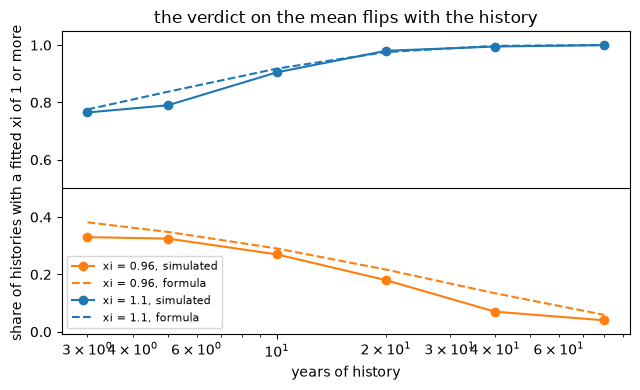

In [17]:
# Draw the share of histories that conclude an infinite mean against the length of the history, with the normal formula
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for xi_true, color in ((0.96, "tab:orange"), (1.1, "tab:blue")):
    shares = [length_rows[(xi_true, y)][2] for y in YEARS_SWEEP]
    formula_values = [length_rows[(xi_true, y)][3] for y in YEARS_SWEEP]
    ax.semilogx(YEARS_SWEEP, shares, "o-", color=color, label="xi = %s, simulated" % xi_true)
    ax.semilogx(YEARS_SWEEP, formula_values, "--", color=color, label="xi = %s, formula" % xi_true)
ax.axhline(0.5, color="black", linewidth=0.8)
ax.set_xlabel("years of history")
ax.set_ylabel("share of histories with a fitted xi of 1 or more")
ax.set_title("the verdict on the mean flips with the history")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The medians of the fitted index sit on the truth at every length (0.954 to 0.961 for a true 0.96, 1.093 to 1.100 for a true 1.10), so the estimator is not biased; what changes is how often one history lands on the wrong side of 1. For the true 0.96 the share at 1 or more is 0.330 with 3 years, 0.270 with 10, 0.180 with 20, 0.070 with 40 and 0.040 with 80, so a bank with ten years concludes an infinite mean that does not exist in 27% of cases and one with 80 years still does in 4%. For the true 1.10 the share, which is now the correct verdict, is 0.765, 0.905, 0.980 and 0.995 at 3, 10, 20 and 40 years, so the finite mean concluded wrongly falls from 9.5% at ten years to 2% at twenty. The formula tracks the simulation within 0.05 for the variant at 1.10, and for 0.96 it overstates the share by up to 0.064 at 40 years (0.134 against 0.070), a reminder that it is a normal approximation of a skewed estimator. The last two printed lines turn it into a requirement: telling 0.96 from 1 with a 5% error needs 6,496 exceedances, about 89 years at the case's 73.2 exceedances a year, while telling 1.10 from 1 needs 1,193, about 14 years. The sweep holds the threshold at EUR 10,000 and a generalised Pareto severity, the family the estimator assumes, and it says nothing about a real tail that is only approximately Pareto.

### Using it on your own data

A bank has one history, not a thousand, so the measurement of this notebook cannot be repeated on it directly: there is no known truth and no independent histories. What can be repeated is the spread of the estimator around its own answer, by resampling the years of the history, which keeps the yearly structure of the counts. The method expects the recorded losses grouped by year as a list of arrays in EUR (years with no recorded loss as empty arrays), the collection threshold, and the number of resamples; it reads no contract document, but its result is judged with the same engine test as the committed rows, `oprisk.capital_stability`, whose reference quantile is here the plug-in capital of the history itself.

The next cell defines `bootstrap_stability`, which for each resample of the years refits the generalised Pareto tail and the Poisson rate with `fit_severity` and `fit_frequency`, computes the single loss approximation with `sla_var`, and passes the 300 capitals to `capital_stability` around the plug-in capital. It is called on a fresh ten-year history of the variant with tail index 0.8 (seed 9,000,017, outside every committed range), and it prints the dispersion beside the committed one over 1,000 independent histories, the share of resamples whose fitted tail index reaches 1, and the true quantile for contrast.

In [18]:
# A function that resamples the years of one history, refits the tail and the rate each time, and runs the
# stability test on the resampled capitals around the plug-in capital, then its call on a fresh history (xi 0.8)
from riskvalidation.oprisk import sla


def bootstrap_stability(amounts_by_year, threshold, n_boot, seed, level=0.999):
    rng_boot = np.random.default_rng(seed)
    counts_own = np.array([a.size for a in amounts_by_year])

    def plug_in(indices):
        amounts_b = np.concatenate([amounts_by_year[i] for i in indices])
        tail = distributions.fit_severity("gpd", amounts_b, threshold, truncated=True)
        rate = distributions.fit_frequency(counts_own[indices]).params[0]
        return sla.sla_var(rate, "gpd", tuple(tail.params), level), tail.params[0]

    base_capital, base_xi = plug_in(np.arange(len(amounts_by_year)))
    pairs = [plug_in(rng_boot.integers(0, len(amounts_by_year), len(amounts_by_year))) for _ in range(n_boot)]
    capitals_b = np.array([p[0] for p in pairs])
    verdict = oprisk_tests.capital_stability(capitals_b, base_capital, model_id="bootstrap")
    return base_capital, base_xi, verdict, float(np.mean([p[1] >= 1.0 for p in pairs]))


own_history = generator.draw_history(variant, 9_000_017, 10).recorded(10_000.0)
by_year = np.split(own_history.amounts, np.cumsum(own_history.counts)[:-1])
base_capital, base_xi, boot_verdict, share_infinite = bootstrap_stability(by_year, 10_000.0, 300, 5)
print("years:", len(by_year), "| losses:", own_history.amounts.size, "| plug-in tail index: %.4f" % base_xi)
print("plug-in capital (EUR):", format(base_capital, ",.0f"), "| true quantile (EUR):", format(true_q, ",.0f"))
print("bootstrap dispersion %.3f | bias %+.3f | light %s | n %d" % (
    boot_verdict.metric, boot_verdict.statistic, boot_verdict.light.value, boot_verdict.n))
print("share of resamples with a fitted tail index of 1 or more:", share_infinite)
print("committed dispersion of the single loss approximation over 1,000 histories, 10 years, EUR 10,000:",
      next(c for c in doc08["outputs"]["cells"] if c["id"] == "y10-h10000")["capital"]["sla"]["iqr_over_truth"])

years: 10 | losses: 658 | plug-in tail index: 0.8342
plug-in capital (EUR): 211,332,714 | true quantile (EUR): 163,483,000
bootstrap dispersion 0.631 | bias -0.012 | light red | n 300
share of resamples with a fitted tail index of 1 or more: 0.0
committed dispersion of the single loss approximation over 1,000 histories, 10 years, EUR 10,000: 0.82282264


Read the output in four steps. First, the history: 10 years and 658 losses, a plug-in tail index of 0.8342 (the true one is 0.80) and a plug-in capital of EUR 211,332,714 against a true quantile of EUR 163,483,000, that is 1.29 times the truth. Second, the bootstrap dispersion of 0.631, with light red, against the 0.823 that the committed cell shows over 1,000 independent histories: the resampling recovers most of the spread (77% of it) from a single history, which is what makes it usable by a bank, and it still understates it. Third, the bootstrap bias of -0.012: it is measured against the plug-in capital, not against the truth, so it is near zero by construction, and it hides the 29% by which the plug-in itself overshoots the truth. A bank without a known truth can measure its spread, never its bias. Fourth, the share of resamples with a fitted tail index of 1 or more is 0.0, so for this history the single loss approximation never loses its mean in the 300 resamples; for a history near 1 this is the number to watch, because the sweep above shows how fast it moves. The bootstrap resamples whole years, so it assumes the years are exchangeable; a trend or a regime change in the bank's losses breaks that assumption and the dispersion is then too small.

## Results

**Answer:** On 16000 independent histories the splice capital has an interquartile range of 1.35 to 3.30 times the true quantile, all 92 committed capital-stability rows are red, and doubling the history from 5 to 10 years at tail index 0.8 and a threshold of EUR 10,000 only takes the committed range from 2.744 to 1.776 (on 40 fresh histories, 6.116 to 1.142). Near a tail index of 1 a bank cannot read its mean from its own data: at 0.96 the share of ten-year histories that call the finite mean infinite is 0.268 and 0.317 in the two committed cells and 0.255 on fresh histories.

- **The design holds.** There are 16 cells and 16,000 histories, none of the 16 seed ranges overlaps another, no replication failed, and the Monte Carlo check of each true quantile has a standard error between 0.51% and 0.99% of it and agrees within three standard errors.
- **Fresh histories agree.** The Fourier recomputation of the true quantile at tail index 0.8 gives EUR 163,483,000, the committed value. On 200 fresh histories per cell the share with a fitted tail index of 1 or more is 0.270 and 0.255 at tail index 0.96 and 0.805 and 0.935 at 1.1 (5 and 10 years), within 0.07 of the committed 0.332, 0.268, 0.818 and 0.912; the engine's threshold-stability test paints 66 of 100 ten-year histories amber at 0.96 and 59 at 1.1, with 13 and 24 red; and the SMA over the truth has medians 4.017, 0.881, 0.240 and 0.077, against 4.030, 0.882, 0.242 and 0.078 committed.
- **The splice is unstable in every cell.** Its bias, median over the truth minus 1, is between -0.07 and -0.50, its interquartile range over the truth between 1.35 and 3.30, and 52% to 60% of the histories underestimate. The rung is defined on 128 to 996 of the 1,000 histories, fewest at tail index 1.1 with 10 years and a threshold of EUR 10,000.
- **Length helps, slowly.** At a threshold of EUR 10,000 the committed range of the splice falls from 1.95 to 1.43, 2.74 to 1.78, 3.10 to 2.11 and 3.30 to 1.68 (tail indices 0.6, 0.8, 0.96 and 1.1) when the history doubles from 5 to 10 years, still of the order of the truth. On 40 fresh histories at tail index 0.8 the engine's test gives a range of 6.12 at 5 years and 1.14 at 10 years for the splice (37 and 39 histories defined) and 1.92 and 0.77 for the approximation, against committed 2.74 and 1.78 and 1.28 and 0.82. With 40 histories the quartiles are noisy; the direction is the same.
- **Wrong conclusions about the mean.** Fitted at the collection threshold, the tail index is 1 or more in 0.0% of the histories of the variant with tail index 0.6, in 0.5% to 6.3% at 0.8, in 26.8% to 34.4% at 0.96 (a finite mean the bank would call infinite) and in 73.2% to 91.2% at 1.1, so 8.8% to 26.8% of those banks would conclude a finite mean where there is none.
- **Not the simulation.** The Monte Carlo error of the truth is under 1% of the quantile, and the Panjer and Fourier aggregations of the same fitted law differ by at most 0.097% over 11,552 histories compared. A dispersion of one to three times the truth comes from estimating the tail on 5 or 10 years of losses.
- **The summary table.** All 92 committed `oprisk.capital_stability` rows are red and none holds a p-value. The standardised approach is stable but far from the truth in the ten-year cells: 4.03 and 3.98 times it at tail index 0.6, 0.87 to 0.88 at 0.8, 0.24 at 0.96 and 0.08 at 1.1.
- **Where it breaks.** At a true tail index of 0.96, 27% of ten-year histories conclude an infinite mean that does not exist and 4% of 80-year ones still do; telling 0.96 from 1 with a 5% error needs 6,496 exceedances, about 89 years at the case's frequency, against 1,193 and 14 years for 1.10.
- **On your own data.** The bootstrap of the years of one history gives a dispersion of 0.631 where the committed cell over 1,000 independent histories gives 0.823, and a bias of -0.012 measured only against the plug-in capital, which itself is 1.29 times the true quantile.

The claim is demonstrated at these numbers, on this generator and with these gates, and no further.

## Summary

- Case C17 measures the stability of operational-risk capital on 16,000 independent histories of a synthetic bank with a known true quantile, over four tail indices, two history lengths and two thresholds.
- The splice rung has an interquartile range of 1.35 to 3.30 times the truth, falling only slowly from 5 to 10 years; the cause is estimating the tail on few years of losses, not the simulation.
- Near a tail index of 1 a bank would often draw the wrong conclusion about whether its mean loss exists: 27% to 34% at 0.96 and 9% to 27% at 1.1.
- The claim is bounded: a synthetic generator, a fixed ladder, internal gates and no real bank.

**What to try next.** Rerun step 3 with 100 histories (about 90 seconds) to narrow the quartiles, or for the variant with tail index 0.96 to see the dispersion of the approximation. Read `docs/design/features/c17/requirements.md` for the requirements that hold the design.

## References

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk. https://www.bis.org/publ/bcbs160.htm
- BCBS (2016), Standardised Measurement Approach for operational risk, consultative document. https://www.bis.org/bcbs/publ/d355.htm
- Chavez-Demoulin, V., Embrechts, P. and Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Peters, G. W., Shevchenko, P. V., Hassani, B. and Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk? https://arxiv.org/abs/1607.02319
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40 (the quantile error of a Monte Carlo decays like the square root of the number of years). https://arxiv.org/abs/1008.1108 and https://doi.org/10.21314/JOP.2010.077